# Exploratory Data Analysis and Linear Regression on Spotify Tracks

    ## Student Details
    Name: Manda Hamsa Lekha

    ## Dataset
    Spotify Tracks Dataset – Audio Features

    ## Source
    Kaggle

    ## Objective
    The objective of this project is to explore the dataset, understand
    its structure and characteristics, clean the data, identify patterns
    and relationships, visualize important findings, and perform Linear
    Regression after the EDA.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df=pd.read_csv('spotify-tracks-dataset-detailed.csv')

In [4]:
df.head()

,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,1,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,1,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,0,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,0,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,2,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


In [5]:
df.tail()

,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
113995,2C3TZjDRiAzdyViavDJ217,Rainy Lullaby,#mindfulness - Soft Rain for Mindful Meditatio...,Sleep My Little Boy,21,384999,False,0.172,0.235,5,-16.393,1,0.0422,0.640,0.928,0.0863,0.0339,125.995,5,world-music
113996,1hIz5L4IB9hN3WRYPOCGPw,Rainy Lullaby,#mindfulness - Soft Rain for Mindful Meditatio...,Water Into Light,22,385000,False,0.174,0.117,0,-18.318,0,0.0401,0.994,0.976,0.1050,0.0350,85.239,4,world-music
113997,6x8ZfSoqDjuNa5SVP5QjvX,Cesária Evora,Best Of,Miss Perfumado,22,271466,False,0.629,0.329,0,-10.895,0,0.0420,0.867,0.000,0.0839,0.7430,132.378,4,world-music
113998,2e6sXL2bYv4bSz6VTdnfLs,Michael W. Smith,Change Your World,Friends,41,283893,False,0.587,0.506,7,-10.889,1,0.0297,0.381,0.000,0.2700,0.4130,135.960,4,world-music
113999,2hETkH7cOfqmz3LqZDHZf5,Cesária Evora,Miss Perfumado,Barbincor,22,241826,False,0.526,0.487,1,-10.204,0,0.0725,0.681,0.000,0.0893,0.7080,79.198,4,world-music


Understand the Dataset

In [7]:
df.shape

(114000, 20)

In [9]:
df.columns

Index(['track_id', 'artists', 'album_name', 'track_name', 'popularity',
       'duration_ms', 'explicit', 'danceability', 'energy', 'key', 'loudness',
       'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness',
       'valence', 'tempo', 'time_signature', 'track_genre'],
      dtype='object')

In [10]:
df.dtypes

,0
track_id,object
artists,object
album_name,object
track_name,object
popularity,int64
duration_ms,int64
explicit,bool
danceability,float64
energy,float64
key,int64


In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 20 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   track_id          114000 non-null  object 
 1   artists           113999 non-null  object 
 2   album_name        113999 non-null  object 
 3   track_name        113999 non-null  object 
 4   popularity        114000 non-null  int64  
 5   duration_ms       114000 non-null  int64  
 6   explicit          114000 non-null  bool   
 7   danceability      114000 non-null  float64
 8   energy            114000 non-null  float64
 9   key               114000 non-null  int64  
 10  loudness          114000 non-null  float64
 11  mode              114000 non-null  int64  
 12  speechiness       114000 non-null  float64
 13  acousticness      114000 non-null  float64
 14  instrumentalness  114000 non-null  float64
 15  liveness          114000 non-null  float64
 16  valence           11

In [12]:
df.describe()

,popularity,duration_ms,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature
count,114000.000000,1.140000e+05,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000
mean,33.238535,2.280292e+05,0.566800,0.641383,5.309140,-8.258960,0.637553,0.084652,0.314910,0.156050,0.213553,0.474068,122.147837,3.904035
std,22.305078,1.072977e+05,0.173542,0.251529,3.559987,5.029337,0.480709,0.105732,0.332523,0.309555,0.190378,0.259261,29.978197,0.432621
min,0.000000,0.000000e+00,0.000000,0.000000,0.000000,-49.531000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,17.000000,1.740660e+05,0.456000,0.472000,2.000000,-10.013000,0.000000,0.035900,0.016900,0.000000,0.098000,0.260000,99.218750,4.000000
50%,35.000000,2.129060e+05,0.580000,0.685000,5.000000,-7.004000,1.000000,0.048900,0.169000,0.000042,0.132000,0.464000,122.017000,4.000000
75%,50.000000,2.615060e+05,0.695000,0.854000,8.000000,-5.003000,1.000000,0.084500,0.598000,0.049000,0.273000,0.683000,140.071000,4.000000
max,100.000000,5.237295e+06,0.985000,1.000000,11.000000,4.532000,1.000000,0.965000,0.996000,1.000000,1.000000,0.995000,243.372000,5.000000


In [13]:
df.nunique()

,0
track_id,89741
artists,31437
album_name,46589
track_name,73608
popularity,101
duration_ms,50697
explicit,2
danceability,1174
energy,2083
key,12


In [14]:
numerical_columns = df.select_dtypes(include=np.number).columns
categorical_columns = df.select_dtypes(include="object").columns

print("Numerical columns:")
print(numerical_columns)

print("\nCategorical columns:")
print(categorical_columns)

Numerical columns:
Index(['popularity', 'duration_ms', 'danceability', 'energy', 'key',
       'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness',
       'liveness', 'valence', 'tempo', 'time_signature'],
      dtype='object')

Categorical columns:
Index(['track_id', 'artists', 'album_name', 'track_name', 'track_genre'], dtype='object')


check duplicates


In [16]:
df.duplicated().sum()

np.int64(450)

In [17]:
df=df.drop_duplicates()

In [18]:
df.shape

(113550, 20)

### Observation

    The dataset initially contained (114000, 20) duplicate records.
    After removing the duplicate records, the dataset contains (113550, 20)
    rows.

Check missing values

In [19]:
df.isnull().sum()

,0
track_id,0
artists,1
album_name,1
track_name,1
popularity,0
duration_ms,0
explicit,0
danceability,0
energy,0
key,0


    The missing-value analysis shows that 3 columns (artists, album_name, and track_name) contain missing values. These missing values need to be handled during the data-cleaning step before further analysis.

In [21]:
df.dropna()

,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,1,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.7150,87.917,4,acoustic
1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,1,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.2670,77.489,4,acoustic
2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,0,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.1200,76.332,4,acoustic
3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,0,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.1430,181.740,3,acoustic
4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,2,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.1670,119.949,4,acoustic
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
113995,2C3TZjDRiAzdyViavDJ217,Rainy Lullaby,#mindfulness - Soft Rain for Mindful Meditatio...,Sleep My Little Boy,21,384999,False,0.172,0.2350,5,-16.393,1,0.0422,0.6400,0.928000,0.0863,0.0339,125.995,5,world-music
113996,1hIz5L4IB9hN3WRYPOCGPw,Rainy Lullaby,#mindfulness - Soft Rain for Mindful Meditatio...,Water Into Light,22,385000,False,0.174,0.1170,0,-18.318,0,0.0401,0.9940,0.976000,0.1050,0.0350,85.239,4,world-music
113997,6x8ZfSoqDjuNa5SVP5QjvX,Cesária Evora,Best Of,Miss Perfumado,22,271466,False,0.629,0.3290,0,-10.895,0,0.0420,0.8670,0.000000,0.0839,0.7430,132.378,4,world-music
113998,2e6sXL2bYv4bSz6VTdnfLs,Michael W. Smith,Change Your World,Friends,41,283893,False,0.587,0.5060,7,-10.889,1,0.0297,0.3810,0.000000,0.2700,0.4130,135.960,4,world-music


In [22]:
df.isnull().sum()

,0
track_id,0
artists,1
album_name,1
track_name,1
popularity,0
duration_ms,0
explicit,0
danceability,0
energy,0
key,0


In [25]:
print(df.shape)


(113550, 20)


In [27]:
df[df.isnull().any(axis=1)]

,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
65900,1kR4gIb7nGxHPI3D2ifs59,NaN,NaN,NaN,0,0,False,0.501,0.583,7,-9.46,0,0.0605,0.69,0.00396,0.0747,0.734,138.391,4,k-pop


In [28]:
df=df.dropna().copy()
print("shape after removing missing values:",df.shape)
print("\nMissing values after cleaning :")
print(df.isnull().sum())

shape after removing missing values: (113549, 20)

Missing values after cleaning :
track_id            0
artists             0
album_name          0
track_name          0
popularity          0
duration_ms         0
explicit            0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
time_signature      0
track_genre         0
dtype: int64


In [30]:
df[df.isnull().any(axis=1)]

,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre


    The missing values were handled by removing the affected rows because only a small number of records contained missing values, and the affected columns contain important track information. After cleaning, no missing values remain in the dataset.

Clean the dataset

In [31]:
df.dtypes

,0
track_id,object
artists,object
album_name,object
track_name,object
popularity,int64
duration_ms,int64
explicit,bool
danceability,float64
energy,float64
key,int64


In [32]:
df_clean=df.copy()

Analyze Categorical Variables

track_genre
acoustic       1000
british        1000
electronic     1000
emo            1000
funk           1000
garage         1000
disco          1000
country        1000
rock           1000
rock-n-roll    1000
Name: count, dtype: int64


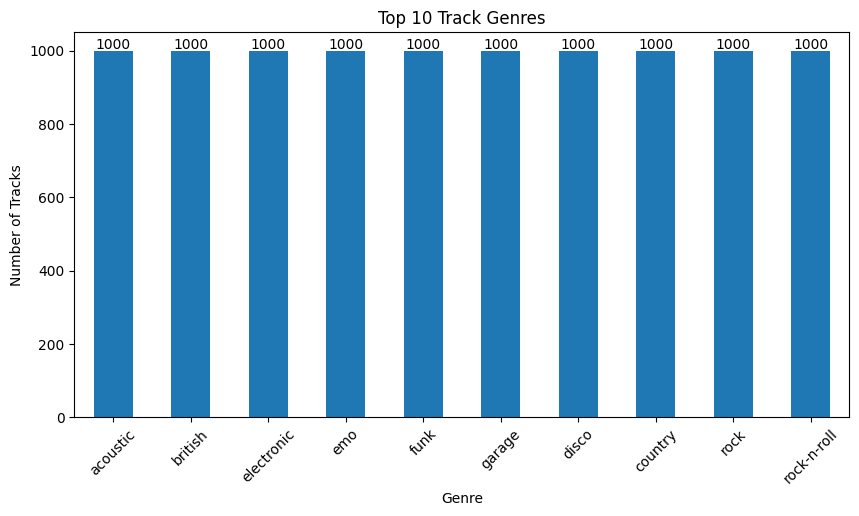

In [48]:
top_genres = df['track_genre'].value_counts().head(10)

print(top_genres)
ax = top_genres.plot(kind='bar', figsize=(10,5))

plt.title("Top 10 Track Genres")
plt.xlabel("Genre")
plt.ylabel("Number of Tracks")
plt.xticks(rotation=45)

for i, value in enumerate(top_genres):
    ax.text(i, value + 5, str(value), ha='center')

plt.show()

explicit
False    103831
True       9718
Name: count, dtype: int64


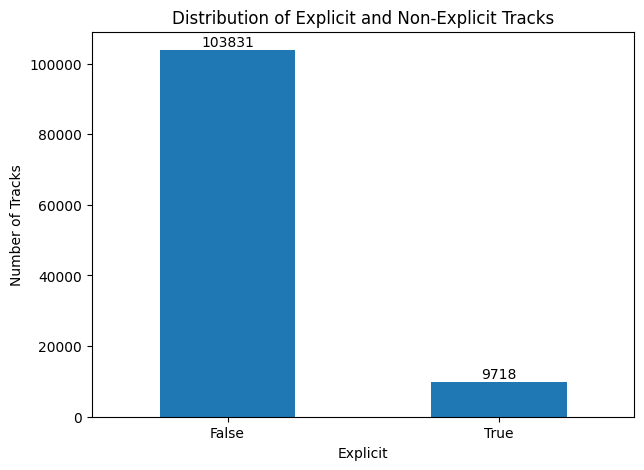

In [38]:
explicit_counts = df['explicit'].value_counts()

print(explicit_counts)
ax = explicit_counts.plot(kind='bar', figsize=(7,5))

plt.title("Distribution of Explicit and Non-Explicit Tracks")
plt.xlabel("Explicit")
plt.ylabel("Number of Tracks")
plt.xticks(rotation=0)

for i, value in enumerate(explicit_counts):
    ax.text(i, value + 1000, str(value), ha='center')

plt.show()

    Observation
    The chart shows that non-explicit tracks are much more common than explicit tracks in the dataset. There are 104,253 non-explicit tracks compared with 9,747 explicit tracks.

Analyze the numerical variables

In [39]:
df.describe()

,popularity,duration_ms,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature
count,113549.000000,1.135490e+05,113549.000000,113549.000000,113549.000000,113549.000000,113549.000000,113549.000000,113549.000000,113549.000000,113549.000000,113549.000000,113549.000000,113549.000000
mean,33.324433,2.280814e+05,0.567031,0.642091,5.309452,-8.243408,0.637866,0.084674,0.314064,0.155703,0.213613,0.474205,122.175745,3.904218
std,22.283855,1.064131e+05,0.173409,0.251053,3.560147,5.011422,0.480620,0.105762,0.331906,0.309217,0.190462,0.259204,29.972954,0.432117
min,0.000000,8.586000e+03,0.000000,0.000000,0.000000,-49.531000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,17.000000,1.741840e+05,0.456000,0.473000,2.000000,-9.998000,0.000000,0.035900,0.016800,0.000000,0.098000,0.260000,99.296000,4.000000
50%,35.000000,2.130000e+05,0.580000,0.685000,5.000000,-6.997000,1.000000,0.048900,0.168000,0.000041,0.132000,0.464000,122.020000,4.000000
75%,50.000000,2.615880e+05,0.695000,0.854000,8.000000,-5.001000,1.000000,0.084500,0.596000,0.048700,0.273000,0.683000,140.074000,4.000000
max,100.000000,5.237295e+06,0.985000,1.000000,11.000000,4.532000,1.000000,0.965000,0.996000,1.000000,1.000000,0.995000,243.372000,5.000000


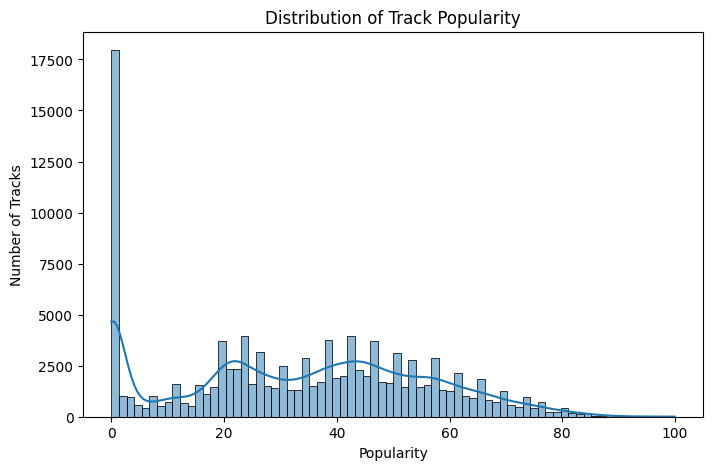

In [40]:
plt.figure(figsize=(8,5))

sns.histplot(df["popularity"], kde=True)

plt.title("Distribution of Track Popularity")
plt.xlabel("Popularity")
plt.ylabel("Number of Tracks")
plt.show()

Outlier Analysis

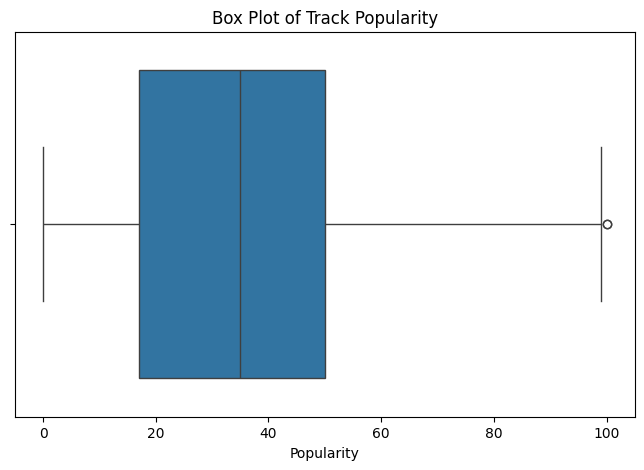

In [41]:
plt.figure(figsize=(8,5))

sns.boxplot(x=df["popularity"])

plt.title("Box Plot of Track Popularity")
plt.xlabel("Popularity")
plt.show()

Univariate Analysis

count    113549.000000
mean         33.324433
std          22.283855
min           0.000000
25%          17.000000
50%          35.000000
75%          50.000000
max         100.000000
Name: popularity, dtype: float64


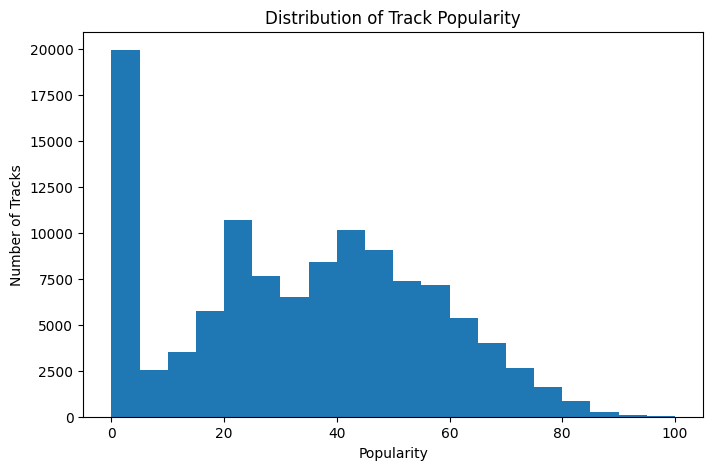

In [42]:
print(df['popularity'].describe())

plt.figure(figsize=(8,5))
plt.hist(df['popularity'], bins=20)
plt.title("Distribution of Track Popularity")
plt.xlabel("Popularity")
plt.ylabel("Number of Tracks")
plt.show()

    Observation: The distribution of track popularity shows that a large number of tracks have very low popularity, particularly near 0. Most of the remaining tracks are distributed across the medium popularity range, while relatively fewer tracks have very high popularity.

count    1.135490e+05
mean     2.280814e+05
std      1.064131e+05
min      8.586000e+03
25%      1.741840e+05
50%      2.130000e+05
75%      2.615880e+05
max      5.237295e+06
Name: duration_ms, dtype: float64


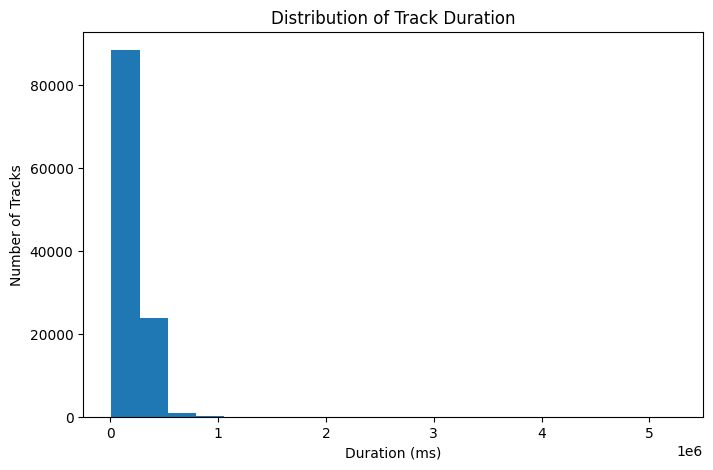

In [43]:
print(df['duration_ms'].describe())

plt.figure(figsize=(8,5))
plt.hist(df['duration_ms'], bins=20)
plt.title("Distribution of Track Duration")
plt.xlabel("Duration (ms)")
plt.ylabel("Number of Tracks")
plt.show()

    Observation: The distribution of track duration is strongly right-skewed. Most tracks have relatively shorter durations, while a small number of tracks have very large duration values, which may indicate the presence of outliers.

count    113549.000000
mean          0.567031
std           0.173409
min           0.000000
25%           0.456000
50%           0.580000
75%           0.695000
max           0.985000
Name: danceability, dtype: float64


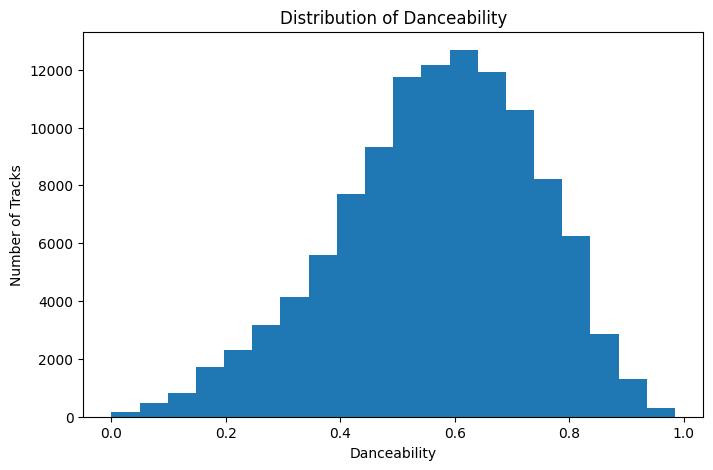

In [44]:
print(df['danceability'].describe())

plt.figure(figsize=(8,5))
plt.hist(df['danceability'], bins=20)
plt.title("Distribution of Danceability")
plt.xlabel("Danceability")
plt.ylabel("Number of Tracks")
plt.show()

    Observation: The distribution of danceability is concentrated mainly between approximately 0.5 and 0.7. Fewer tracks have very low or very high danceability values, indicating that most tracks in the dataset have moderate to high danceability.

Bivariate Analysis

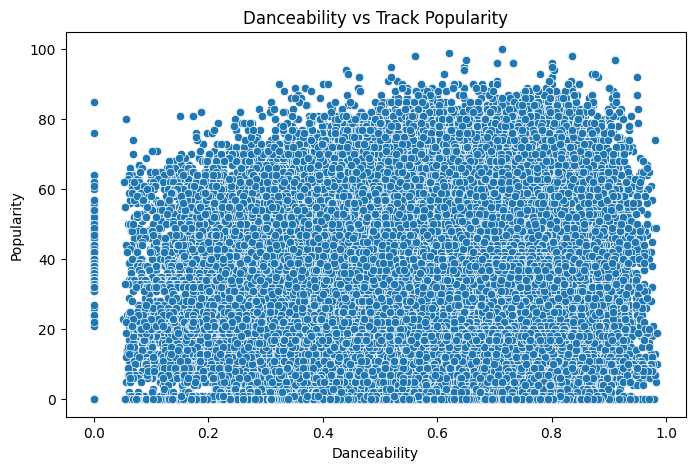

In [45]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df,
    x="danceability",
    y="popularity"
)

plt.title("Danceability vs Track Popularity")
plt.xlabel("Danceability")
plt.ylabel("Popularity")
plt.show()

    Observation: The scatter plot indicates that the relationship between danceability and popularity appears weak.

Multivariate Analysis

In [46]:
corr = df.select_dtypes(include=np.number).corr()

corr


,popularity,duration_ms,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature
popularity,1.000000,-0.007928,0.034407,-0.002447,-0.004167,0.047368,-0.015009,-0.045463,-0.022356,-0.094718,-0.005668,-0.041097,0.012187,0.030567
duration_ms,-0.007928,1.000000,-0.074117,0.058160,0.008519,-0.004233,-0.035961,-0.063194,-0.103676,0.125301,0.010199,-0.154795,0.024312,0.018351
danceability,0.034407,-0.074117,1.000000,0.131694,0.036546,0.256559,-0.069783,0.108236,-0.169181,-0.183974,-0.131651,0.476755,-0.051517,0.207370
energy,-0.002447,0.058160,0.131694,1.000000,0.048047,0.760624,-0.079331,0.141976,-0.732747,-0.179967,0.184810,0.258451,0.247361,0.186671
key,-0.004167,0.008519,0.036546,0.048047,1.000000,0.038359,-0.135871,0.020820,-0.041124,-0.006819,-0.001518,0.034233,0.010903,0.015122
loudness,0.047368,-0.004233,0.256559,0.760624,0.038359,1.000000,-0.042074,0.060088,-0.588111,-0.432109,0.076792,0.279428,0.212181,0.191648
mode,-0.015009,-0.035961,-0.069783,-0.079331,-0.135871,-0.042074,1.000000,-0.046773,0.096548,-0.050787,0.013900,0.021411,0.000371,-0.024365
speechiness,-0.045463,-0.063194,0.108236,0.141976,0.020820,0.060088,-0.046773,1.000000,-0.001378,-0.089214,0.205092,0.036393,0.017167,-0.000397
acousticness,-0.022356,-0.103676,-0.169181,-0.732747,-0.041124,-0.588111,0.096548,-0.001378,1.000000,0.102134,-0.020313,-0.106240,-0.207620,-0.175621
instrumentalness,-0.094718,0.125301,-0.183974,-0.179967,-0.006819,-0.432109,-0.050787,-0.089214,0.102134,1.000000,-0.079847,-0.324314,-0.049939,-0.081951


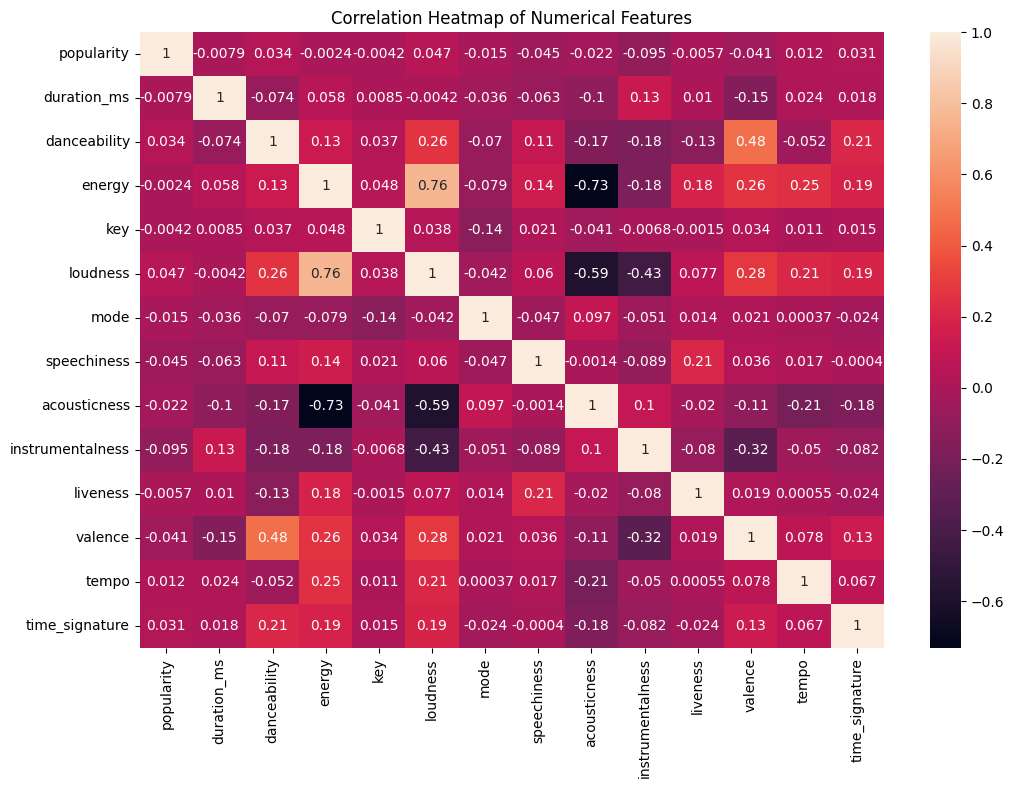

In [47]:
plt.figure(figsize=(12,8))

sns.heatmap(corr, annot=True)

plt.title("Correlation Heatmap of Numerical Features")
plt.show()

    Observation: The correlation heatmap shows that energy and loudness have a relatively strong positive relationship, while danceability shows a relatively weak relationship with popularity.

## Key Insights

1. The dataset contains a large number of non-explicit tracks compared with explicit tracks.

2. Track popularity is unevenly distributed, with a large number of tracks having very low popularity.

3. Track duration is strongly right-skewed, with most tracks having shorter durations and a small number of tracks having very large duration values.

4. Danceability values are concentrated mainly around the moderate-to-high range, particularly between approximately 0.5 and 0.7.

5. Energy and loudness show a relatively strong positive relationship, while danceability has a relatively weak relationship with popularity.

6. The genre distribution is balanced, with each genre containing approximately 1000 tracks.


##LINEAR REGRESSION


Linear regression is used to study whether a numerical feature can be used
to predict the popularity of a track.

In [49]:
# Check correlation of numerical variables with popularity

correlation = df.select_dtypes(include='number').corr()['popularity'].sort_values(ascending=False)

print(correlation)

popularity          1.000000
loudness            0.047368
danceability        0.034407
time_signature      0.030567
tempo               0.012187
energy             -0.002447
key                -0.004167
liveness           -0.005668
duration_ms        -0.007928
mode               -0.015009
acousticness       -0.022356
valence            -0.041097
speechiness        -0.045463
instrumentalness   -0.094718
Name: popularity, dtype: float64


In [51]:
X = df[['energy']]
y = df['popularity']

In [52]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [56]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)
y_pred=model.predict(X_test)

In [57]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R² Score:", r2)

MAE: 18.969042871880305
MSE: 501.6166187641697
RMSE: 22.396799297314107
R² Score: -5.688770317924252e-06


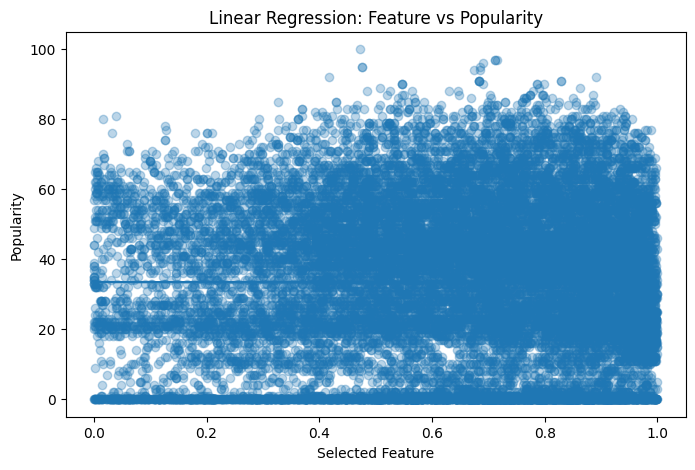

In [58]:
plt.figure(figsize=(8,5))

plt.scatter(X_test, y_test, alpha=0.3)
plt.plot(X_test, y_pred)

plt.title("Linear Regression: Feature vs Popularity")
plt.xlabel("Selected Feature")
plt.ylabel("Popularity")

plt.show()

##LIMITATIONS

    The analysis is based on the available Spotify track dataset and its recorded audio features. The analysis identifies relationships and patterns in the data but does not establish cause-and-effect relationships. Some unusual values may also require further investigation to determine whether they represent genuine tracks or data irregularities.

##CONCLUSION
    This project explored the Spotify Tracks dataset through data cleaning, descriptive statistics, univariate analysis, bivariate analysis, multivariate analysis, and visualization. The analysis helped identify patterns in track popularity, duration, danceability, explicit content, and other audio features. Correlation analysis was used to examine relationships between numerical variables, and linear regression was performed to study the relationship between the selected feature and popularity. Overall, the project provided an understanding of the structure, distribution, relationships, and patterns present in the dataset.